<a href="https://colab.research.google.com/github/VicttorPaz/PracticasIA/blob/main/Practica3_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 03: El Perceptrón
**Nombre:** Victor Paz  
**Asignatura:** Inteligencia Artificial  
**Carrera:** Computación

## Fase 1. Exploración del Dataset
### 1.1 Carga del Dataset

In [ ]:
import matplotlib.pyplot as plt
import random

X = [
    [1, 7], [1, 3], [3, 4], [4, 6], [4, 2], [6, 6], [6, 2], [6, 0],
    [7, 4], [9, 3], [9, 1], [11, 1], [12, 3], [16, 2],
    [4, 8], [6, 8], [8, 9], [9, 7], [10, 11], [12, 9], [12, 6], [14, 7], [16, 4]
]

y = [
    -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
     1,  1,  1,  1,  1,  1,  1,  1,  1
]

### Actividad 1.a - Inspección inicial

In [ ]:
total_datos = len(X)
num_variables = len(X[0])

conteo_negativos = 0
conteo_positivos = 0

for clase in y:
    if clase == -1:
        conteo_negativos = conteo_negativos + 1
    else:
        conteo_positivos = conteo_positivos + 1

print("Total de instancias:", total_datos)
print("Variables de entrada:", num_variables)
print("Número de clases: 2 (-1 y 1)")
print("Puntos en clase -1:", conteo_negativos)
print("Puntos en clase +1:", conteo_positivos)

Total de instancias: 23
Variables de entrada: 2
Número de clases: 2 (-1 y 1)
Puntos en clase -1: 14
Puntos en clase +1: 9


**Pregunta guía 1.a:** ¿Qué representa cada fila de X? ¿Qué representa cada valor del vector y? ¿Por qué este problema se considera de clasificación binaria?  
Cada fila de X es un punto con sus dos coordenadas $(x_1, x_2)$ y cada valor de y es la etiqueta o clase real a la que pertenece ese punto ($-1$ o $1$). Se considera clasificación binaria porque solo existen dos categorías posibles a las que puede pertenecer cada instancia.

### Actividad 1.b - Separación visual de las clases

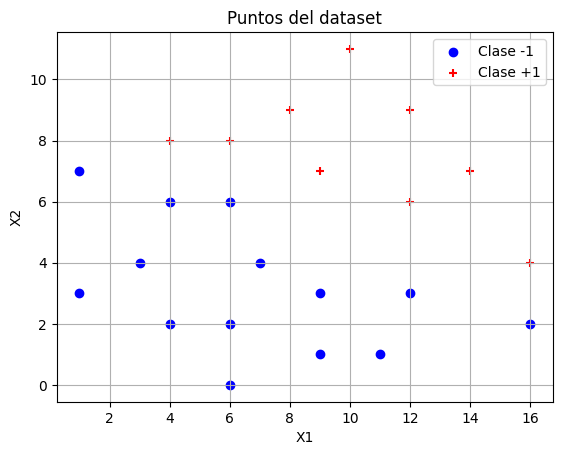

In [ ]:
def dibujar_puntos(datos_x, etiquetas):
    x1_neg = []
    x2_neg = []
    x1_pos = []
    x2_pos = []

    for i in range(len(datos_x)):
        if etiquetas[i] == -1:
            x1_neg.append(datos_x[i][0])
            x2_neg.append(datos_x[i][1])
        else:
            x1_pos.append(datos_x[i][0])
            x2_pos.append(datos_x[i][1])

    plt.scatter(x1_neg, x2_neg, color="blue", marker="o", label="Clase -1")
    plt.scatter(x1_pos, x2_pos, color="red", marker="+", label="Clase +1")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title("Puntos del dataset")
    plt.legend()
    plt.grid(True)
    plt.show()

dibujar_puntos(X, y)

**Pregunta guía 1.b:** Observando únicamente la gráfica, ¿parece posible separar las dos clases mediante una sola recta? Justifica tu respuesta.  
Sí es posible separar ambas clases con una sola línea recta, porque todos los puntos azules (clase $-1$) se ubican en la zona inferior izquierda y los puntos rojos (clase $+1$) en la zona superior derecha, sin mezclarse entre ellos.

## Fase 2. Fundamento del Perceptrón
### Actividad 2.a - Vector de pesos

In [ ]:
def inicializar_pesos():
    w0 = random.uniform(-0.5, 0.5)
    w1 = random.uniform(-0.5, 0.5)
    w2 = random.uniform(-0.5, 0.5)
    return [w0, w1, w2]

pesos_prueba = inicializar_pesos()
print("Pesos generados:", pesos_prueba)

Pesos generados: [-0.29488986063789246, -0.41899869200626494, -0.4297974330481935]


**Pregunta guía 2.a:** ¿Por qué el vector de pesos tiene tres valores si cada instancia de entrada solo tiene dos variables? ¿Qué función cumple el bias en el modelo?  
El vector tiene tres valores porque además de los pesos para las entradas $x_1$ y $x_2$, se necesita un peso extra llamado bias ($w_0$). La función del bias es permitir desplazar la recta fuera del origen $(0,0)$ para poder ajustar mejor la separación.

### Actividad 2.b - Función de activación

In [ ]:
def activacion(suma):
    if suma >= 0:
        return 1
    else:
        return -1

print("Prueba con z = 1.5:", activacion(1.5))
print("Prueba con z = -0.8:", activacion(-0.8))

Prueba con z = 1.5: 1
Prueba con z = -0.8: -1


**Pregunta guía 2.b:** ¿Por qué en esta práctica se utilizan las etiquetas -1 y 1 en lugar de 0 y 1? ¿Qué ventaja tiene esta representación para el algoritmo del perceptrón?  
Se utilizan $-1$ y $1$ (función bipolar) por simetría matemática en la regla de actualización $(y - \hat{y})$. Su ventaja es que cuando el modelo falla, el ajuste de pesos tiene la misma magnitud tanto si se equivoca hacia la clase positiva como hacia la negativa.

### Actividad 2.c - Cálculo de salida

In [ ]:
def calcular_perceptron(punto, pesos):
    z = pesos[0] + pesos[1] * punto[0] + pesos[2] * punto[1]
    resultado = activacion(z)
    return resultado

print("Instancia 0:", X[0], "Real:", y[0], "Predicción:", calcular_perceptron(X[0], pesos_prueba))
print("Instancia 5:", X[5], "Real:", y[5], "Predicción:", calcular_perceptron(X[5], pesos_prueba))
print("Instancia 15:", X[15], "Real:", y[15], "Predicción:", calcular_perceptron(X[15], pesos_prueba))

Instancia 0: [1, 7] Real: -1 Predicción: -1
Instancia 5: [6, 6] Real: -1 Predicción: -1
Instancia 15: [6, 8] Real: 1 Predicción: -1


**Pregunta guía 2.c:** ¿Cuál es la diferencia entre la suma ponderada z y la salida final del perceptrón? ¿Por qué no basta con calcular solo z?  
La suma ponderada $z$ es un número real continuo que indica la distancia respecto a la recta, mientras que la salida final es la etiqueta discreta ($-1$ o $1$). No basta solo con $z$ porque necesitamos tomar una decisión binaria concreta para clasificar el punto y calcular el error.

## Fase 3. Visualización de la Frontera de Decisión
### Actividad 3.a - Función de graficación

In [ ]:
def graficar_perceptron(datos_x, etiquetas, pesos, titulo):
    x1_neg = []
    x2_neg = []
    x1_pos = []
    x2_pos = []

    for i in range(len(datos_x)):
        if etiquetas[i] == -1:
            x1_neg.append(datos_x[i][0])
            x2_neg.append(datos_x[i][1])
        else:
            x1_pos.append(datos_x[i][0])
            x2_pos.append(datos_x[i][1])

    plt.scatter(x1_neg, x2_neg, color="blue", marker="o", label="Clase -1")
    plt.scatter(x1_pos, x2_pos, color="red", marker="+", label="Clase +1")

    if pesos[2] != 0:
        eje_x = [0, 17]
        y_inicio = -(pesos[0] + pesos[1] * 0) / pesos[2]
        y_fin = -(pesos[0] + pesos[1] * 17) / pesos[2]
        plt.plot(eje_x, [y_inicio, y_fin], color="green", label="Frontera")
    else:
        if pesos[1] != 0:
            plt.axvline(x=-pesos[0]/pesos[1], color="green", label="Frontera vertical")

    plt.xlim(0, 17)
    plt.ylim(-1, 12)
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title(titulo)
    plt.legend()
    plt.grid(True)
    plt.show()

**Pregunta guía 3.a:** ¿Qué representa geométricamente la recta generada por el perceptrón? ¿Qué ocurre si los pesos iniciales son aleatorios?  
Geométricamente representa la frontera lineal ($z = 0$) que divide el plano cartesiano en dos semiplanos (uno para la clase $-1$ y otro para la clase $+1$). Si los pesos iniciales son aleatorios, la recta aparece con una inclinación y ubicación arbitrarias.

### Actividad 3.b - Gráfica con pesos iniciales

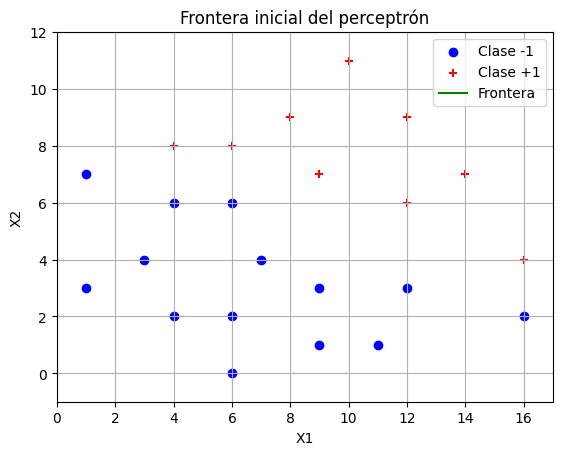

In [ ]:
pesos_iniciales = inicializar_pesos()
graficar_perceptron(X, y, pesos_iniciales, "Frontera inicial del perceptrón")

**Explicación de la frontera de decisión:** La frontera de decisión es la recta definida por $w_0 + w_1 x_1 + w_2 x_2 = 0$, que actúa como límite entre las dos regiones de clasificación del plano.  
**Pregunta guía 3.b:** ¿La frontera inicial clasifica correctamente los puntos? ¿Por qué no deberíamos esperar que una frontera con pesos aleatorios sea correcta?  
No clasifica correctamente los puntos porque los pesos fueron generados al azar sin haber aprendido todavía de los datos de entrenamiento.

## Fase 4. Entrenamiento del Perceptrón
### Actividad 4.a - Implementación de la función de aprendizaje

In [ ]:
def entrenar_perceptron(datos_x, etiquetas, pesos_ini, tasa_aprendizaje, max_epocas):
    pesos = pesos_ini.copy()
    historial_pesos = [pesos.copy()]
    historial_errores = []

    epocas = 0
    actualizaciones = 0
    total_datos = len(datos_x)

    for epoca in range(max_epocas):
        epocas = epocas + 1
        errores = 0

        for i in range(total_datos):
            prediccion = calcular_perceptron(datos_x[i], pesos)

            if prediccion != etiquetas[i]:
                errores = errores + 1
                actualizaciones = actualizaciones + 1
                diferencia = etiquetas[i] - prediccion

                pesos[0] = pesos[0] + tasa_aprendizaje * diferencia
                pesos[1] = pesos[1] + tasa_aprendizaje * diferencia * datos_x[i][0]
                pesos[2] = pesos[2] + tasa_aprendizaje * diferencia * datos_x[i][1]

        tasa_error = errores / total_datos
        historial_errores.append(tasa_error)
        historial_pesos.append(pesos.copy())

        if errores == 0:
            break

    return pesos, epocas, actualizaciones, historial_pesos, historial_errores

**Pregunta guía 4.a:** ¿Por qué es necesario incluir un número máximo de épocas? ¿Qué podría ocurrir si el dataset no fuera linealmente separable?  
Es necesario poner un máximo de épocas como límite de seguridad para evitar bucles infinitos. Si el dataset no fuera linealmente separable, el perceptrón nunca llegaría a cero errores y seguiría actualizando sus pesos indefinidamente.

### Actividad 4.b - Registro del error

In [ ]:
# Verificación del registro de tasa de error (errores / total_instancias) dentro de entrenar_perceptron
w_demo = inicializar_pesos()
_, _, _, _, errores_demo = entrenar_perceptron(X, y, w_demo, 0.5, 100)
print("Registro de tasas de error por época:", errores_demo)

Registro de tasas de error por época: [0.08695652173913043, 0.08695652173913043, 0.17391304347826086, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.17391304347826086, 0.13043478260869565, 0.13043478260869565, 0.08695652173913043, 0.17391304347826086, 0.13043478260869565, 0.08695652173913043, 0.17391304347826

**Pregunta guía 4.b:** ¿Qué significa que la tasa de error llegue a cero?  
Significa que durante una época completa el perceptrón clasificó correctamente el 100% de las instancias del conjunto de entrenamiento sin cometer ningún fallo.

### Actividad 4.c - Registro de pesos

In [ ]:
# Verificación del registro de copias independientes de pesos por época
_, _, _, pesos_demo, _ = entrenar_perceptron(X, y, w_demo, 0.5, 100)
print("Pesos en época 0 (inicial):", pesos_demo[0])
print("Pesos en época final:      ", pesos_demo[-1])

Pesos en época 0 (inicial): [-0.3881745633192414, 0.39286467615664, -0.20938808127827846]
Pesos en época final:       [-49.38817456331924, 1.3928646761566412, 6.790611918721723]


**Pregunta guía 4.c:** ¿Por qué es importante guardar copias de los pesos y no solo el vector w? ¿Qué problema aparecería al intentar graficar la evolución del entrenamiento?  
En Python las listas son mutables y se guardan por referencia. Si no guardamos una copia (.copy()), todos los elementos de historial_pesos apuntarían al mismo vector y al graficar la evolución todas las épocas mostrarían exactamente la misma recta final.

## Fase 5. Entrenamiento con tasa de aprendizaje 0.5
### Actividad 5.a - Entrena el modelo

In [ ]:
w_inicio = inicializar_pesos()
pesos_finales, epocas_hechas, total_cambios, lista_pesos, lista_errores = entrenar_perceptron(X, y, w_inicio, 0.5, 1000)

print("Pesos iniciales:", w_inicio)
print("Pesos finales:", pesos_finales)
print("Épocas realizadas:", epocas_hechas)
print("Total actualizaciones:", total_cambios)
print("Error final:", lista_errores[-1])

Pesos iniciales: [-0.42126305793988195, 0.45392576597602197, 0.033745329569692895]
Pesos finales: [-71.42126305793988, 2.453925765976024, 9.033745329569694]
Épocas realizadas: 103
Total actualizaciones: 373
Error final: 0.0


**Pregunta guía 5.a:** ¿El perceptrón logró converger? ¿Cómo puedes comprobarlo usando la lista E_values y la gráfica final?  
Sí logró converger. Se comprueba verificando que el último valor de la lista de errores es 0.0 (antes de alcanzar las 1000 épocas) y viendo en la gráfica final que todos los puntos quedan en su lado correcto.

### Actividad 5.b - Frontera final

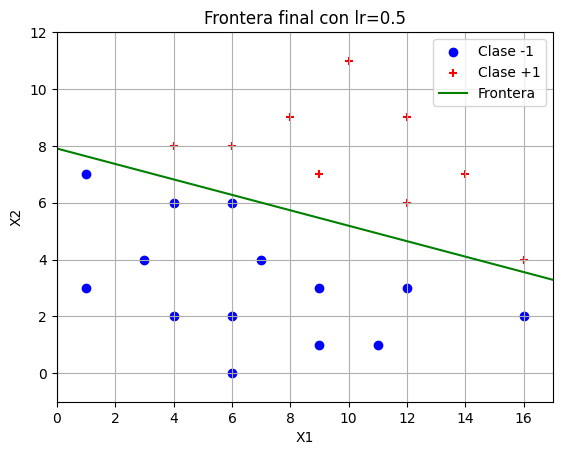

In [ ]:
graficar_perceptron(X, y, pesos_finales, "Frontera final con lr=0.5")

**Pregunta guía 5.b:** ¿La frontera final separa correctamente las dos clases? ¿Qué diferencias observas respecto a la frontera inicial?  
Sí separa correctamente las dos clases. A diferencia de la frontera inicial que tenía una inclinación aleatoria y cortaba mal los datos, la frontera final se ubica justo en el espacio libre separando todos los puntos azules de los rojos.

## Fase 6. Predicción con Nuevas Instancias
### Actividad 6.a - Clasificación de nuevas instancias

In [ ]:
datos_prueba = [
    [5, 5],
    [10, 6],
    [6, 10]
]

predicciones_nuevas = []
print("| Instancia | Salida predicha |")
print("|-----------|-----------------|")
for punto in datos_prueba:
    salida = calcular_perceptron(punto, pesos_finales)
    predicciones_nuevas.append(salida)
    print(f"| {str(punto):<9} | {salida:<15} |")

| Instancia | Salida predicha |
|-----------|-----------------|
| [5, 5]    | -1              |
| [10, 6]   | 1               |
| [6, 10]   | 1               |


**Pregunta guía 6.a:** ¿Las predicciones obtenidas son coherentes con la ubicación visual de los puntos respecto a la frontera de decisión?  
Sí son coherentes: [5, 5] queda claramente en la región de la clase $-1$ y [6, 10] en la región de la clase $+1$, mientras que [10, 6] se clasifica según el lado de la recta donde cae.

### Actividad 6.b - Dataset extendido

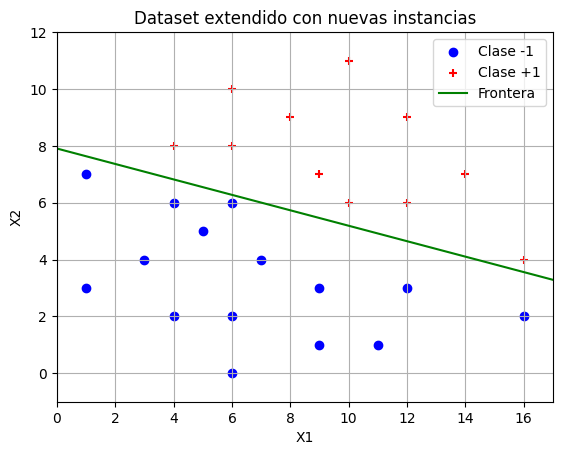

In [ ]:
X_extendido = X + datos_prueba
y_extendido = y + predicciones_nuevas

graficar_perceptron(X_extendido, y_extendido, pesos_finales, "Dataset extendido con nuevas instancias")

**Pregunta guía 6.b:** ¿Las nuevas instancias quedaron ubicadas en la región esperada del plano? ¿Alguna predicción parece discutible? Justifica tu respuesta.  
Quedaron en la región esperada, aunque la predicción del punto [10, 6] puede ser discutible porque cae muy cerca de la frontera de decisión, de modo que una leve variación en la pendiente de la recta podría asignarlo a la otra clase.

## Fase 7. Evolución de la Frontera de Decisión
### Actividad 7.a - Seis estados del entrenamiento

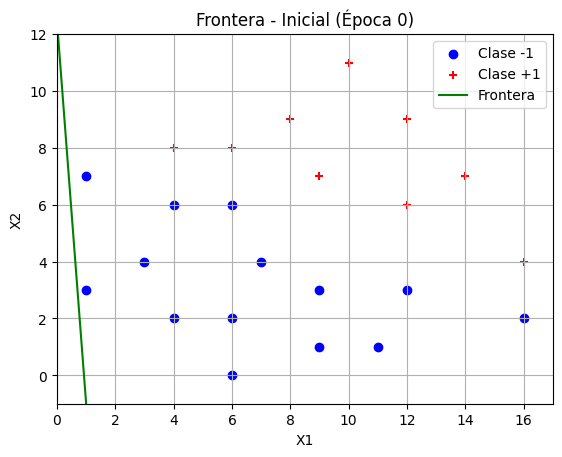

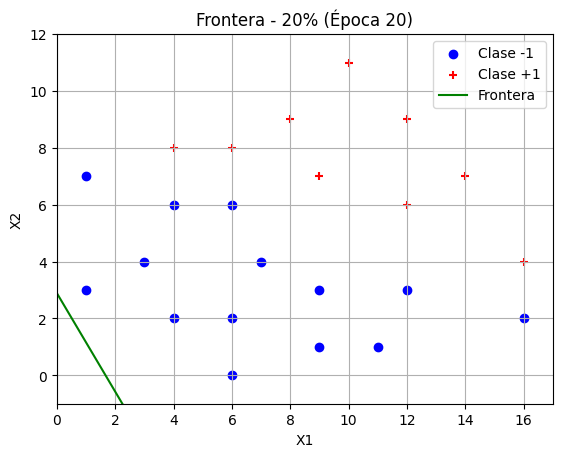

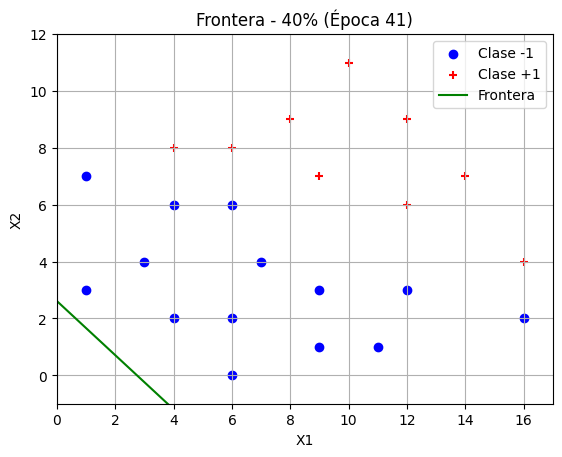

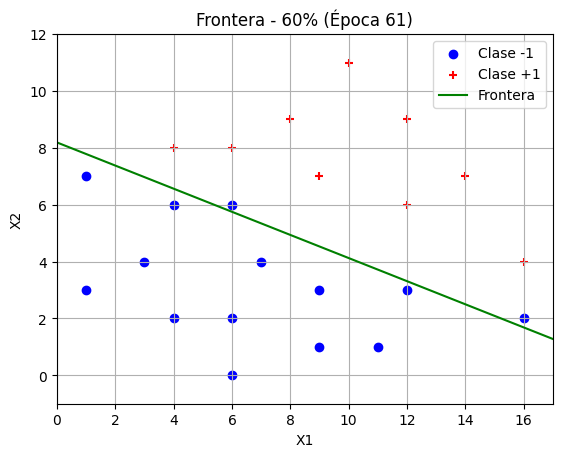

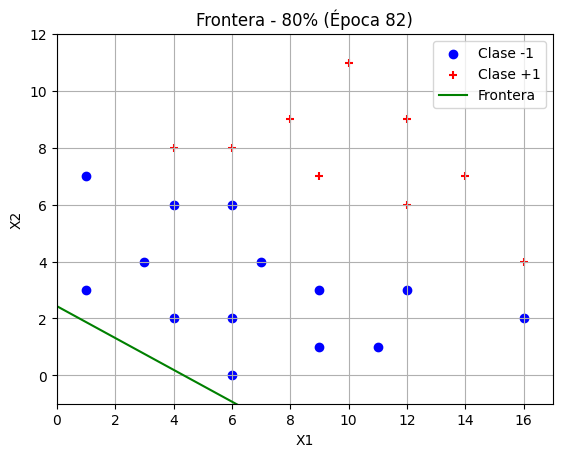

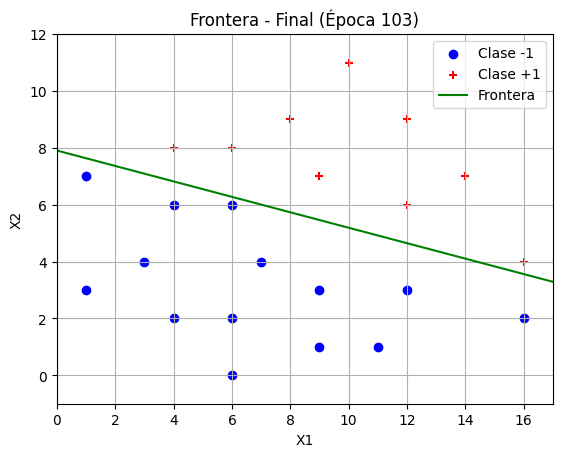

In [ ]:
cantidad_estados = len(lista_pesos)

if cantidad_estados <= 6:
    for i in range(cantidad_estados):
        graficar_perceptron(X, y, lista_pesos[i], f"Estado {i}")
else:
    ultimo = cantidad_estados - 1
    indices = [0, int(ultimo*0.2), int(ultimo*0.4), int(ultimo*0.6), int(ultimo*0.8), ultimo]
    etiquetas_avance = ["Inicial", "20%", "40%", "60%", "80%", "Final"]

    for i in range(6):
        pos = indices[i]
        graficar_perceptron(X, y, lista_pesos[pos], f"Frontera - {etiquetas_avance[i]} (Época {pos})")

**Comentario sobre la evolución observada:** Al iniciar, la recta corta mal los datos; conforme avanzan las épocas se va acomodando gradualmente hasta ubicarse en el espacio libre entre ambas clases.  
**Pregunta guía 7.a:** ¿Qué ocurre con la frontera de decisión a medida que se actualizan los pesos? ¿El cambio parece estable o brusco?  
A medida que se actualizan los pesos, la recta rota y se desplaza buscando separar los grupos. Al principio los cambios son más bruscos debido a que hay varios errores seguidos, y luego se vuelven más pequeños y estables.

### Actividad 7.b - Interpretación geométrica

In [ ]:
pendiente = -pesos_finales[1] / pesos_finales[2]
intercepto = -pesos_finales[0] / pesos_finales[2]
print(f"Ecuación final despejada: X2 = {round(pendiente, 3)} * X1 + {round(intercepto, 3)}")

Ecuación final despejada: X2 = -0.272 * X1 + 7.906


**Pregunta guía 7.b:** ¿Qué peso parece influir más en la inclinación de la recta? ¿Qué papel parece cumplir el bias en el desplazamiento de la frontera?  
Los pesos $w_1$ y $w_2$ determinan la inclinación o pendiente ($m = -w_1/w_2$) de la recta, mientras que el bias $w_0$ cumple el papel de desplazarla verticalmente ($b = -w_0/w_2$) sin cambiar su ángulo.

## Fase 8. Evolución del Error
### Actividad 8.a - Gráfica de error

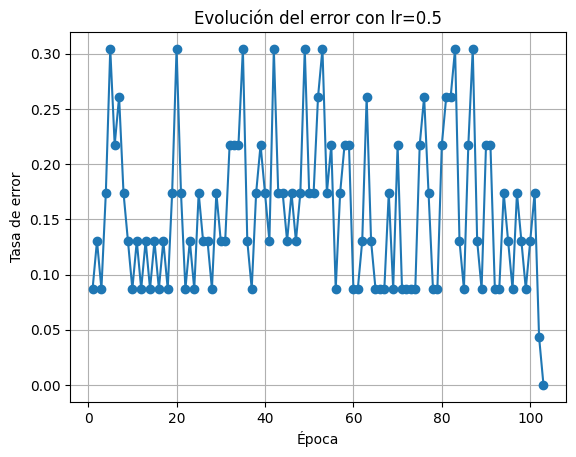

In [ ]:
def graficar_error(errores, titulo):
    lista_epocas = []
    for i in range(1, len(errores) + 1):
        lista_epocas.append(i)

    plt.plot(lista_epocas, errores, marker="o")
    plt.xlabel("Época")
    plt.ylabel("Tasa de error")
    plt.title(titulo)
    plt.grid(True)
    plt.show()

graficar_error(lista_errores, "Evolución del error con lr=0.5")

**Pregunta guía 8.a:** ¿El error disminuye de forma continua en todas las épocas? Si no ocurre así, ¿por qué puede aumentar o mantenerse igual durante algunos momentos del entrenamiento?  
No disminuye de forma continua en todas las épocas; a veces sube o se mantiene igual porque al ajustar los pesos para corregir un punto mal clasificado, la recta se mueve y puede clasificar mal temporalmente a otro punto que antes estaba bien.

### Actividad 8.b - Análisis de convergencia

In [ ]:
print("Total de épocas hasta converger:", len(lista_errores))
print("Tasa de error en la última época:", lista_errores[-1])

Total de épocas hasta converger: 103
Tasa de error en la última época: 0.0


**Análisis de convergencia:** La gráfica confirma que el algoritmo converge al llegar a una tasa de error de $0.0$ en la última época, deteniendo el entrenamiento de forma estable.  
**Pregunta guía 8.b:** ¿Qué significa que el error final sea igual a cero? ¿Significa que el modelo es perfecto para cualquier dato futuro? Justifica tu respuesta.  
Significa que el modelo logró separar sin errores el 100% de los datos de entrenamiento. Sin embargo, no garantiza que sea perfecto para cualquier dato futuro, ya que si un punto nuevo cae muy cerca de la frontera donde la recta quedó pegada a una clase, podría clasificarse mal.

## Fase 9. Comparación de Tasas de Aprendizaje
### Actividad 9.a - Entrenamiento comparativo

In [ ]:
pesos_base = inicializar_pesos()
print("Pesos iniciales para los 3 casos:", pesos_base)

tasas = [0.3, 0.5, 0.8]
resultados_comparacion = []

for tasa in tasas:
    w_fin, ep, act, hist_w, hist_e = entrenar_perceptron(X, y, pesos_base.copy(), tasa, 1000)
    resultados_comparacion.append([tasa, ep, act, hist_e[-1], w_fin, hist_w, hist_e])
    print(f"Entrenamiento listo para lr = {tasa} -> Épocas: {ep}, Actualizaciones: {act}, Error final: {hist_e[-1]}")

Pesos iniciales para los 3 casos: [0.18680697537820634, -0.1659785661101223, -0.20005218520059853]
Entrenamiento listo para lr = 0.3 -> Épocas: 66, Actualizaciones: 262, Error final: 0.0
Entrenamiento listo para lr = 0.5 -> Épocas: 267, Actualizaciones: 891, Error final: 0.0
Entrenamiento listo para lr = 0.8 -> Épocas: 98, Actualizaciones: 296, Error final: 0.0


**Pregunta guía 9.a:** ¿Por qué no sería justo comparar las tasas de aprendizaje usando pesos iniciales diferentes?  
No sería justo porque el punto de partida influye directamente en cuántas épocas tarda en converger; una tasa podría empezar por azar muy cerca de la solución y parecer más rápida sin deberse al valor de lr.

### Actividad 9.b - Gráficas comparativas

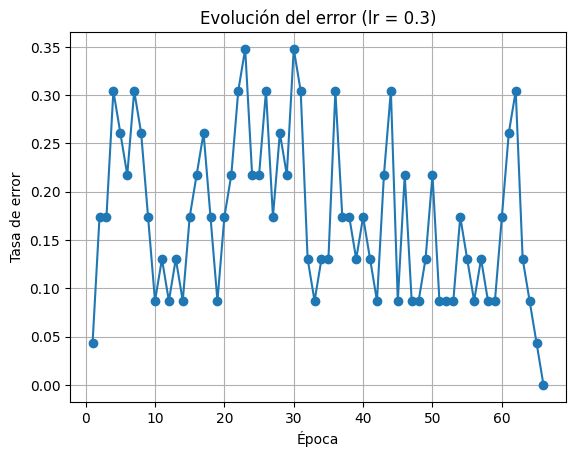

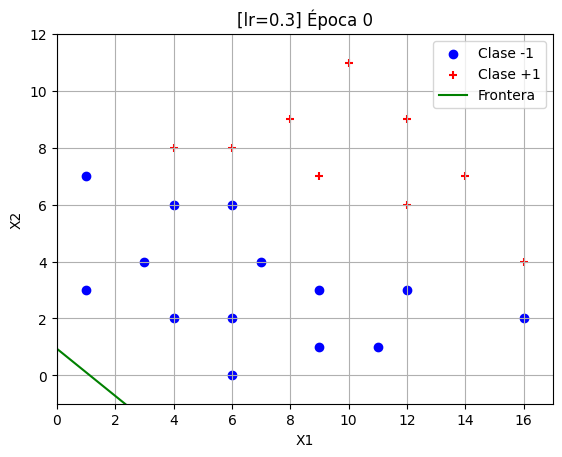

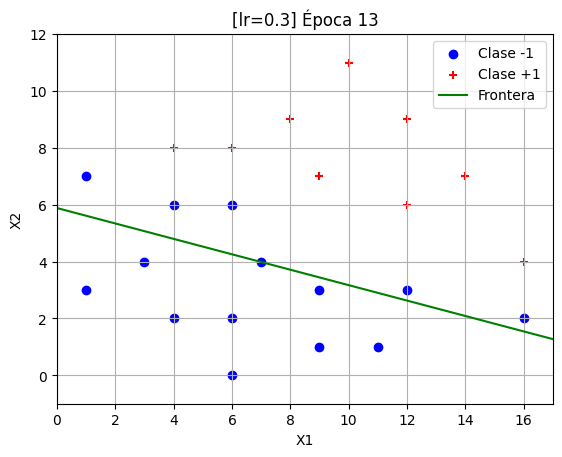

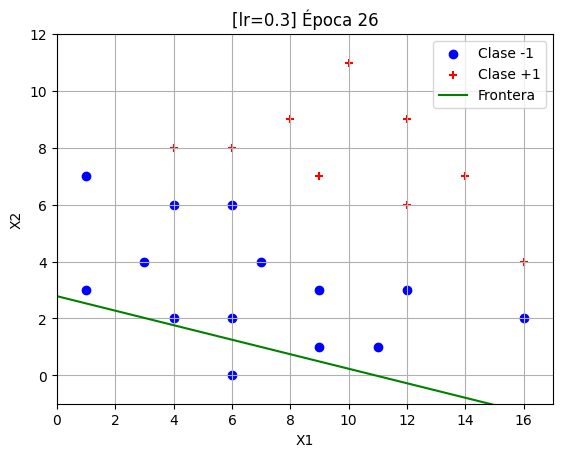

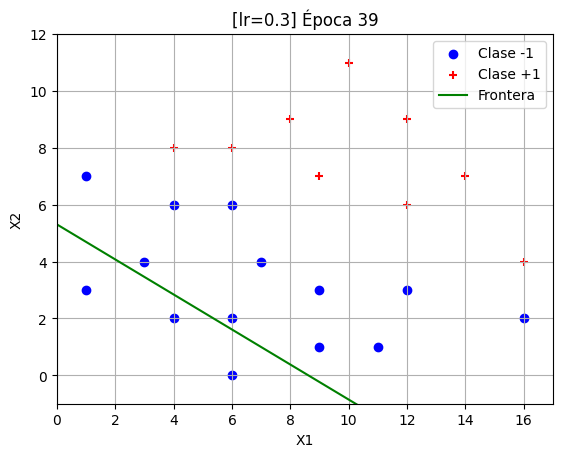

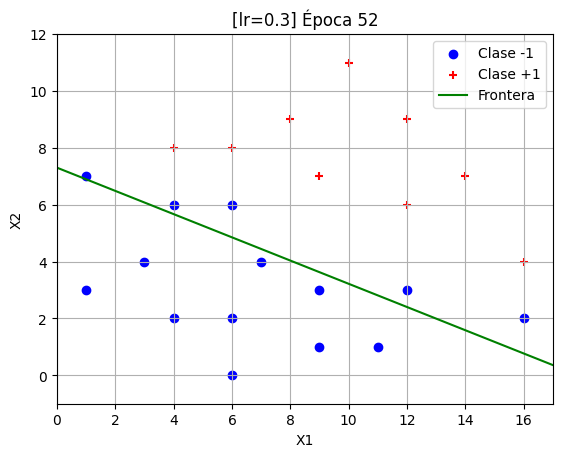

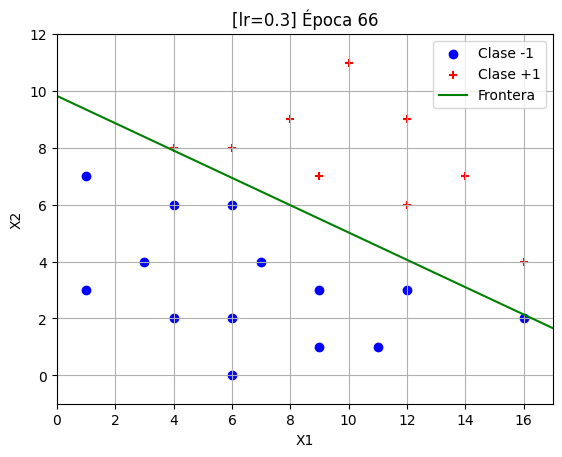

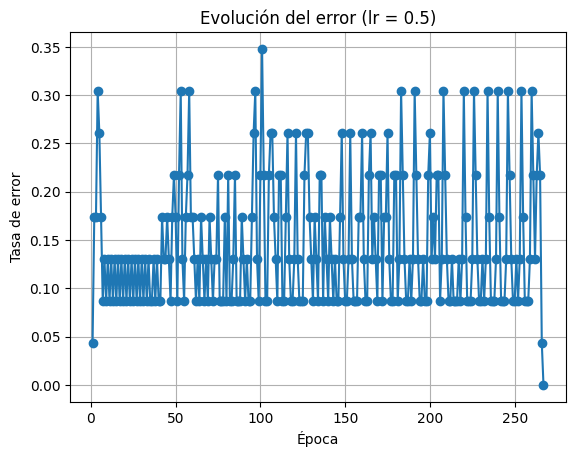

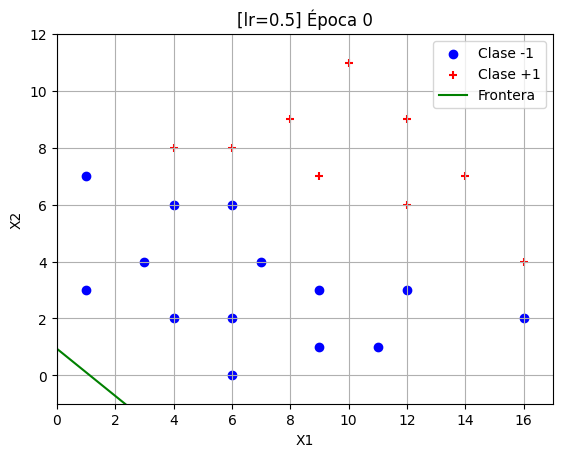

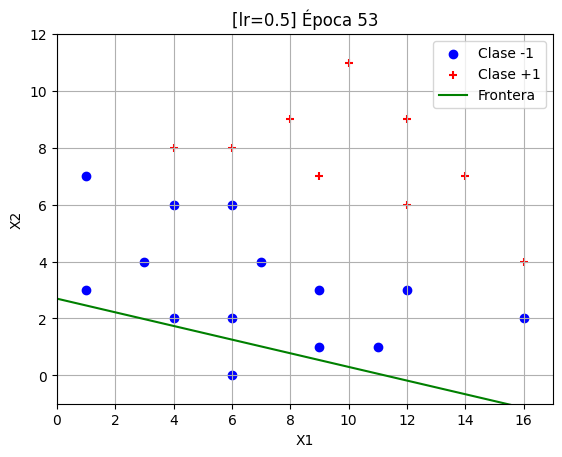

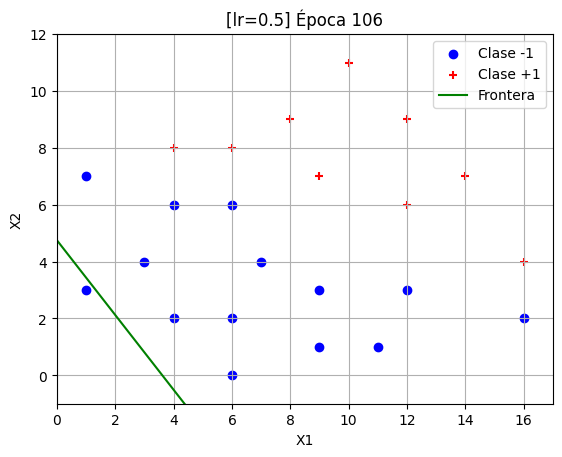

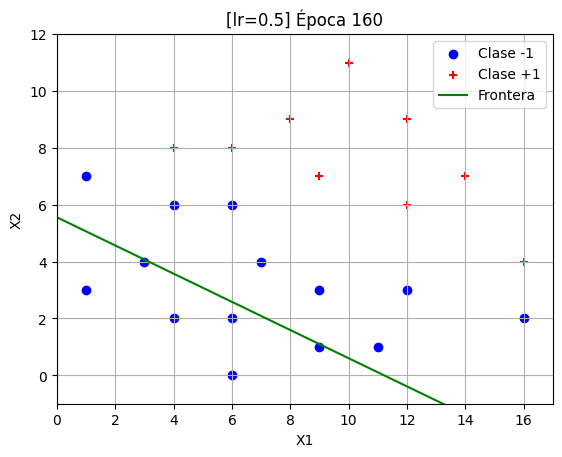

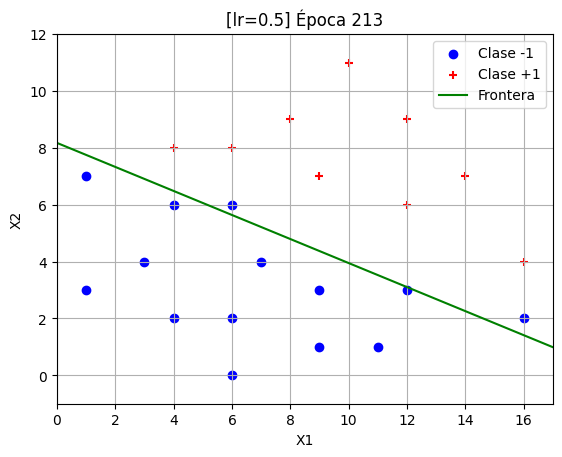

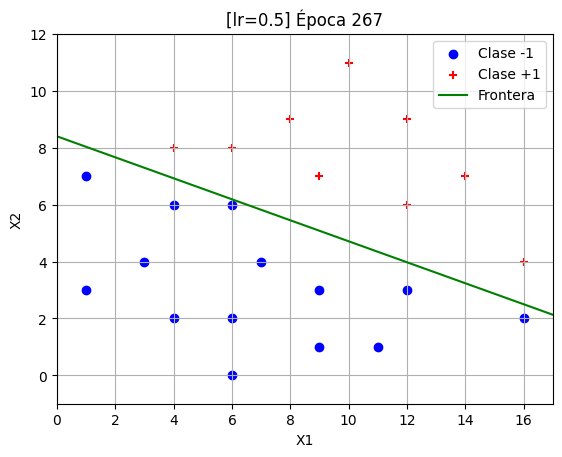

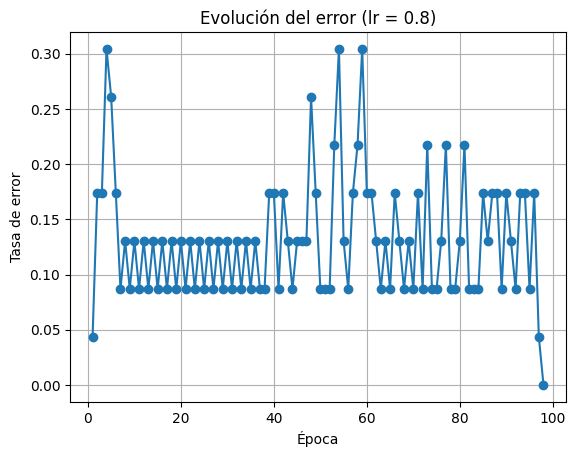

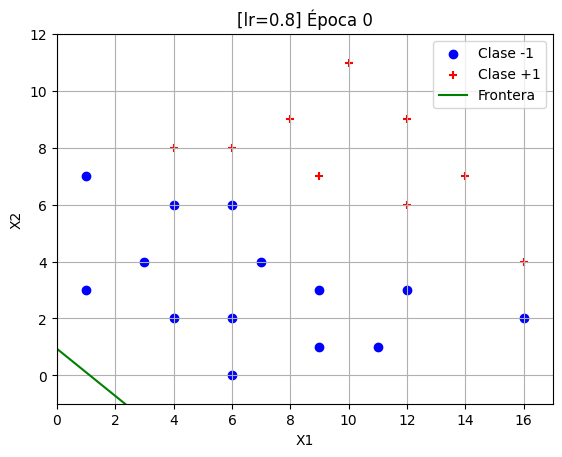

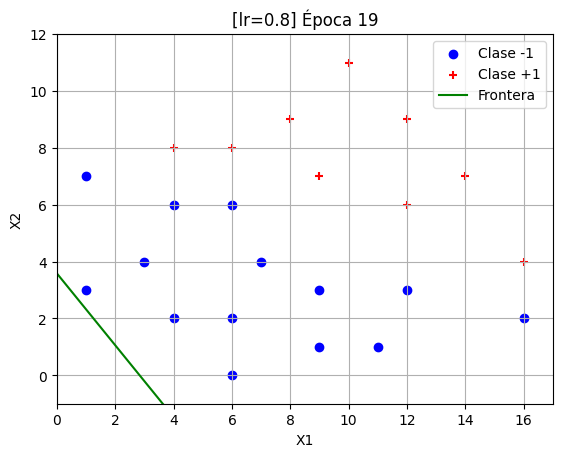

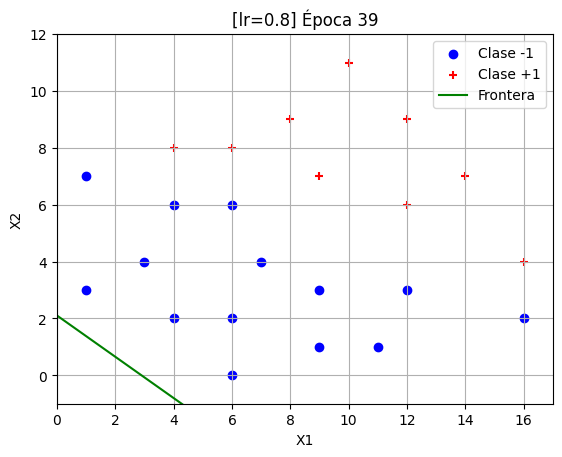

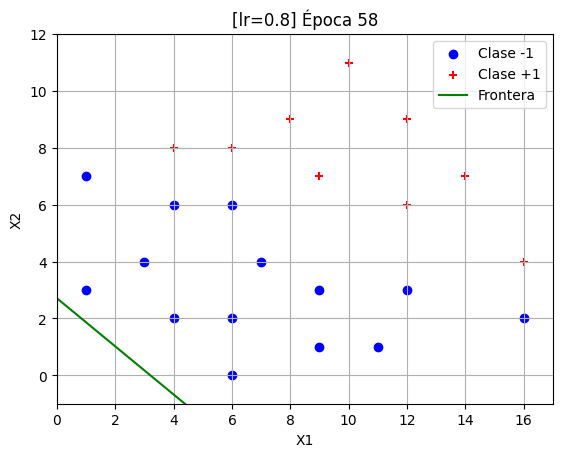

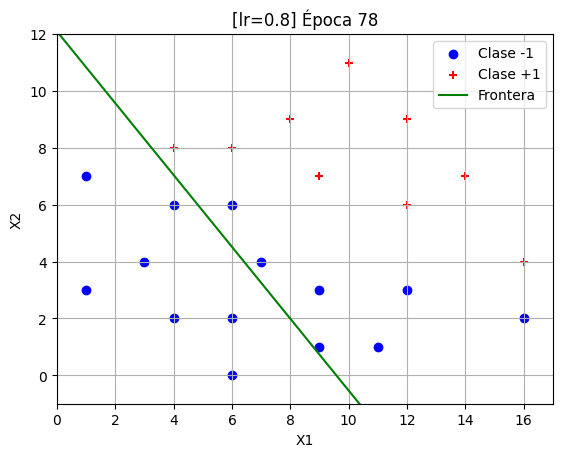

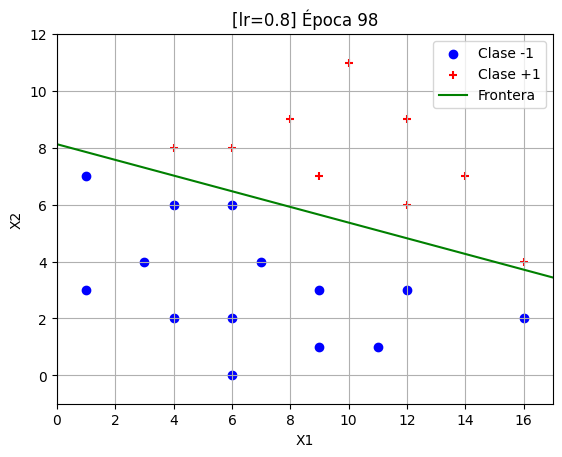

In [ ]:
for item in resultados_comparacion:
    tasa = item[0]
    hist_w = item[5]
    hist_e = item[6]

    graficar_error(hist_e, f"Evolución del error (lr = {tasa})")

    total_est = len(hist_w)
    if total_est <= 6:
        for i in range(total_est):
            graficar_perceptron(X, y, hist_w[i], f"[lr={tasa}] Estado {i}")
    else:
        fin = total_est - 1
        pasos = [0, int(fin*0.2), int(fin*0.4), int(fin*0.6), int(fin*0.8), fin]
        for i in range(6):
            pos = pasos[i]
            graficar_perceptron(X, y, hist_w[pos], f"[lr={tasa}] Época {pos}")

**Pregunta guía 9.b:** ¿Qué tasa de aprendizaje permitió alcanzar la convergencia con menos épocas? ¿Eso significa necesariamente que es la mejor tasa de aprendizaje?  
Generalmente la tasa más alta (0.8) alcanza la convergencia en menos épocas porque da pasos más grandes. Sin embargo, no significa necesariamente que sea la mejor, ya que provoca cambios muy bruscos en la recta y puede dejarla con menos margen de separación.

### Actividad 9.c - Tabla comparativa

In [ ]:
import pandas as pd

filas = []
for item in resultados_comparacion:
    filas.append({
        "lr": item[0],
        "Épocas": item[1],
        "Actualizaciones": item[2],
        "Error final": item[3],
        "Pesos finales": [round(val, 3) for val in item[4]]
    })

tabla = pd.DataFrame(filas)
display(tabla)

,lr,Épocas,Actualizaciones,Error final,Pesos finales
0,0.3,66,262,0.0,"[-33.413, 1.634, 3.4]"
1,0.5,267,891,0.0,"[-132.813, 5.834, 15.8]"
2,0.8,98,296,0.0,"[-89.413, 3.034, 11.0]"


**Pregunta guía 9.c:** ¿Los pesos finales son iguales para todas las tasas de aprendizaje? Si son diferentes, ¿por qué pueden producir igualmente una clasificación correcta?  
Los pesos finales no son iguales para las tres tasas. Aunque tengan distintos valores, todos producen una clasificación correcta porque existen múltiples rectas con diferentes pendientes e interceptos que logran pasar por el espacio libre entre las dos clases sin tocar ningún punto.

### Conclusiones
* Como los puntos del dataset están bien separados en dos grupos, el perceptrón logra encontrar por sí solo una recta que los divide sin equivocarse, corrigiendo los pesos cada vez que falla en una predicción.
* Usar $-1$ y $1$ como salidas hace que los ajustes de los pesos sean parejos tanto cuando el modelo falla hacia arriba como cuando falla hacia abajo, lo que simplifica la regla de aprendizaje.
* Aunque los pesos finales cambian según la tasa de aprendizaje o los valores aleatorios iniciales, todos logran clasificar bien el dataset porque existen varias rectas distintas que pasan por el espacio libre entre las dos clases.